# Text RAG: ViDoRe V3 Industrial

Loads the `vidore/vidore_v3_industrial` dataset from Hugging Face.

Each config has a single `test` split:

| config | contents |
|---|---|
| `corpus` | one row per page: `corpus_id`, `image`, `doc_id`, `markdown`, `page_number_in_doc` |
| `queries` | `query_id`, `query`, `answer`, `query_types`, ... |
| `qrels` | relevance labels linking `query_id` to `corpus_id` (with `score`, `bounding_boxes`), used as the retrieval ground truth |

In [11]:
!pip install -q datasets pillow pandas matplotlib


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Load and Inspect dataset

In [1]:
from datasets import load_dataset

ds_corpus = load_dataset("vidore/vidore_v3_industrial", "corpus")
ds_labels = load_dataset("vidore/vidore_v3_industrial", "qrels")
ds_queries = load_dataset("vidore/vidore_v3_industrial", "queries")

C:\Users\ASUS\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Keep only the English queries.
ds_queries["test"] = ds_queries["test"].filter(lambda lang: lang == "english", input_columns="language")

kept_ids = set(ds_queries["test"]["query_id"])
ds_labels["test"] = ds_labels["test"].filter(lambda qid: qid in kept_ids, input_columns="query_id")
print(f"kept {len(ds_queries['test'])} English queries and {len(ds_labels['test'])} qrels rows")

kept 283 English queries and 1614 qrels rows


In [3]:
for name, ds in [("corpus", ds_corpus), ("queries", ds_queries), ("qrels", ds_labels)]:
    print(f"{name}: {len(ds['test'])} rows, columns {list(ds['test'].features)}")

corpus: 5244 rows, columns ['corpus_id', 'image', 'doc_id', 'markdown', 'page_number_in_doc']
queries: 283 rows, columns ['query_id', 'query', 'language', 'query_types', 'query_format', 'content_type', 'raw_answers', 'query_generator', 'query_generation_pipeline', 'source_type', 'query_type_for_generation', 'answer']
qrels: 1614 rows, columns ['query_id', 'corpus_id', 'score', 'content_type', 'bounding_boxes']


AFD-091005-056 page 0
TO 00-25-172CL-2
TECHNICAL MANUAL
CHECKLIST
CONCURRENT SERVICING OF COMMERCIAL CONTRACT CARGO AIRCRA


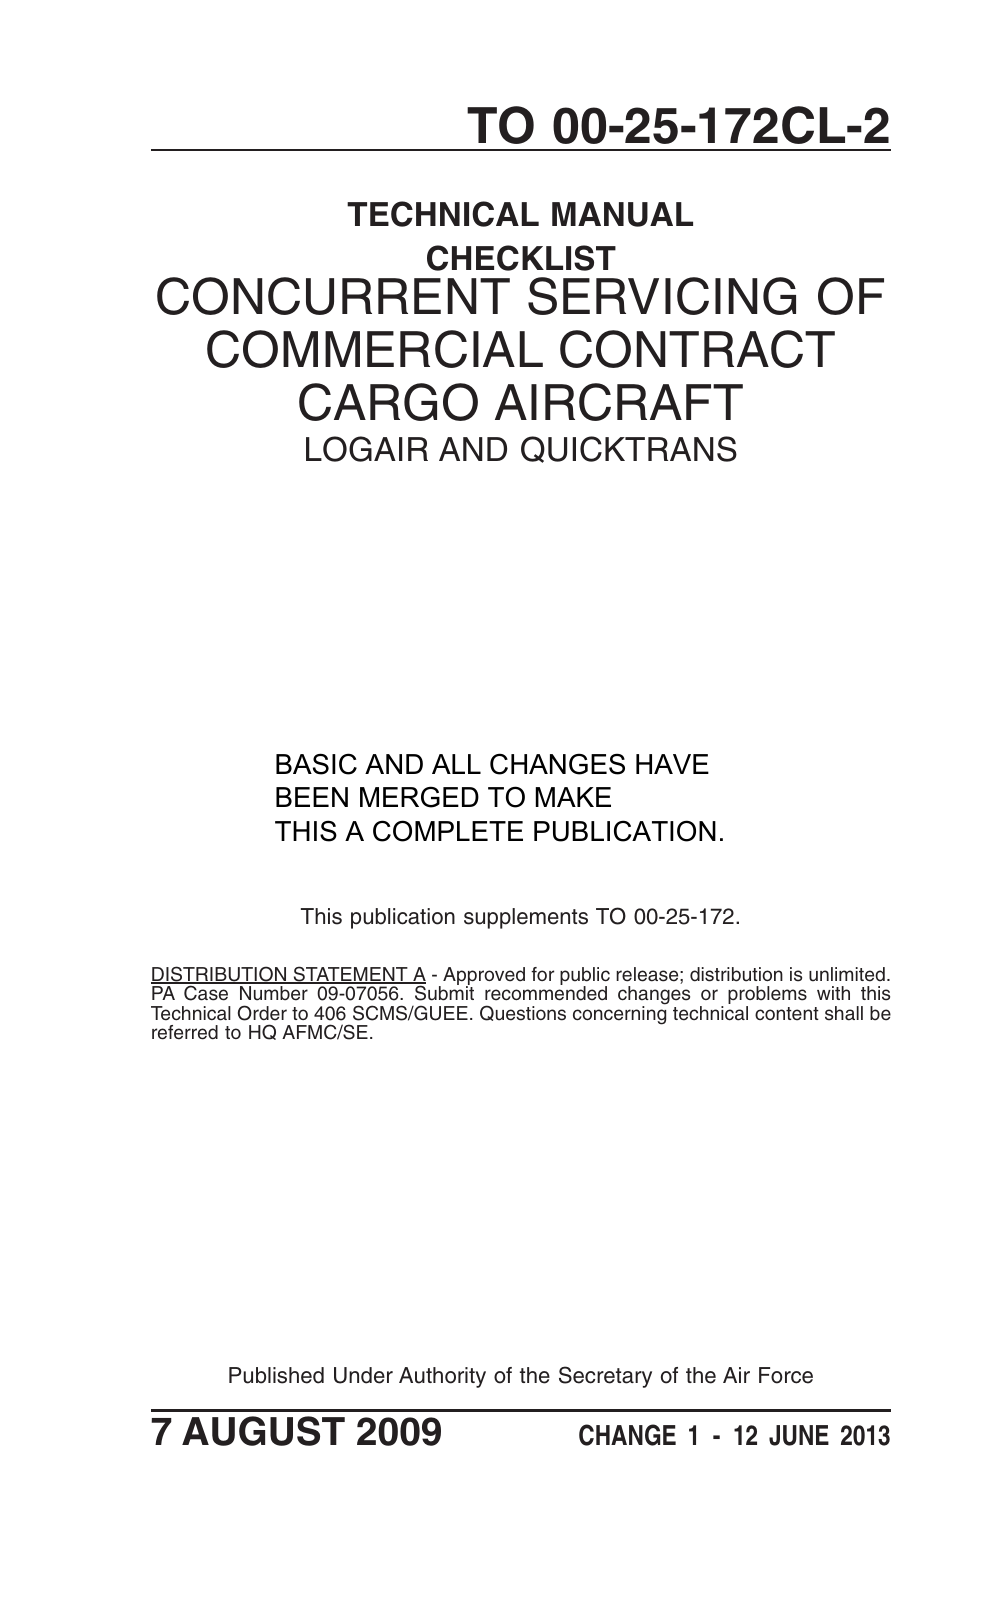

In [4]:
# A sample corpus page: image + OCR/markdown text
from IPython.display import display

page = ds_corpus["test"][0]
print(page["doc_id"], "page", page["page_number_in_doc"])
print(page["markdown"][:100])
display(page["image"])

In [5]:
# A sample query with its relevant pages
q = ds_queries["test"][0]
relevant = [r["corpus_id"] for r in ds_labels["test"] if r["query_id"] == q["query_id"]]

print("query:", q["query"])
print("answer:", q["answer"])
print("relevant corpus_ids:", relevant)

query: Which components are involved in the emergency shutdown procedure and what are their roles in ensuring system isolation?
answer: The components involved in the emergency shutdown procedure are the Pneumatic System and the N2 Bottle Cylinder, which power the emergency shutdown system. The Radio Remote Control System Keypad is used to activate the emergency shutdown and stop fuel flow. The E-Stop Switch is used to initiate an emergency shutdown. The Globe valve controls the propane flow, and the Pilot valve controls the COAX valve. The Control stand contains the valves.
relevant corpus_ids: [53, 163, 166, 175, 208, 214, 220, 222, 225, 226]


In [6]:
from collections import defaultdict

def build_qrels(qrels) -> dict[int, set[int]]:
    out = defaultdict(set)
    for row in qrels:
        if row["score"] > 0:
            out[row["query_id"]].add(row["corpus_id"])
    return dict(out)

qrels_by_query = build_qrels(ds_labels["test"])  # query_id -> relevant corpus_ids (retrieval ground truth)

print(f"{len(qrels_by_query)} queries with relevance labels")

283 queries with relevance labels


## Retrieval setup

Each page's `markdown` is indexed as one document, so the retrieval unit is the same as the unit in the page-level `qrels`. `to_pages` turns a score per page into a ranked list of `corpus_id`s.

In [4]:
!pip install -q bm25s PyStemmer "sentence-transformers" "transformers"


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import numpy as np

# Read columns directly: iterating rows would decode every page image just to get the id and text.
page_ids = ds_corpus["test"]["corpus_id"]
page_texts = [text or "" for text in ds_corpus["test"]["markdown"]]
print(f"{len(page_texts)} pages")


def to_pages(page_scores: np.ndarray, k: int) -> list[int]:
    """Ranked list of the top-k page corpus_ids for one score per page."""
    return [page_ids[i] for i in np.argsort(-page_scores)[:k]]

5244 pages


## Sparse retrieval (keyword, BM25s)

Scores pages by weighted keyword overlap with the query using [`bm25s`](https://github.com/xhluca/bm25s). Text is lowercased, English stopwords are dropped and words are stemmed, so "servicing" and "service" match. It is strong on exact terms such as part numbers and manual codes, and blind to synonyms.

In [8]:
import bm25s
import Stemmer

stemmer = Stemmer.Stemmer("english")

bm25 = bm25s.BM25()
bm25.index(bm25s.tokenize(page_texts, stopwords="en", stemmer=stemmer))

def sparse_pages(query: str, k: int) -> list[int]:
    # return_ids=False gives plain string tokens, which get_scores maps through the index vocabulary
    q_tokens = bm25s.tokenize(query, stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)[0]
    return to_pages(bm25.get_scores(q_tokens), k)

## Dense retrieval (semantic)

Embeds every page with `Qwen/Qwen3-Embedding-0.6B` (1024-dim, 32k context, instruction-aware) and ranks by cosine similarity to the query embedding. Queries are prefixed with a task instruction, documents are not. It matches meaning rather than exact words.

In [9]:
import torch
from pathlib import Path
from sentence_transformers import SentenceTransformer

EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
# Qwen3-Embedding is instruction-aware: queries get a task prompt, documents are embedded as-is.
QUERY_PROMPT = "Instruct: Given a question about a technical manual, retrieve the page that answers it\nQuery:"
MAX_SEQ_LENGTH = 2048  # whole pages; longer pages are truncated
EMBED_CACHE = Path(f"page_emb_{EMBED_MODEL.split('/')[-1]}_{MAX_SEQ_LENGTH}.npy")

device = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(EMBED_MODEL, device=device, tokenizer_kwargs={"padding_side": "left"})
embedder.max_seq_length = MAX_SEQ_LENGTH
if device == "cuda":
    embedder.half()

# Page embeddings are the slow step, so they are cached on disk. The model is still loaded above for query encoding.
if EMBED_CACHE.exists() and np.load(EMBED_CACHE, mmap_mode="r").shape[0] == len(page_texts):
    page_emb = np.load(EMBED_CACHE)
    print(f"Loaded page embeddings from {EMBED_CACHE}")
else:
    page_emb = embedder.encode(page_texts, batch_size=4, normalize_embeddings=True, show_progress_bar=True)
    np.save(EMBED_CACHE, page_emb)
    print(f"Saved page embeddings to {EMBED_CACHE}")


def dense_pages(query: str, k: int) -> list[int]:
    q_emb = embedder.encode(query, prompt=QUERY_PROMPT, normalize_embeddings=True)
    # Dot product of the query vector with every page vector. Both are normalised to length 1,
    # so this equals cosine similarity: one score per page, higher means more similar.
    scores = np.dot(page_emb, q_emb)
    return to_pages(scores, k)

The `tokenizer_kwargs` argument was renamed and is now deprecated. Please use `processor_kwargs` instead.
Loading weights: 100%|██████████| 310/310 [00:01<00:00, 155.28it/s]
This model was loaded in torch.bfloat16 on CPU. Depending on your CPU, inference may be significantly slower than with torch.float32. Consider comparing inference speeds by loading with `model_kwargs={"dtype": torch.float32}`.


Loaded page embeddings from page_emb_Qwen3-Embedding-0.6B_2048.npy


## Hybrid retrieval (sparse + dense, RRF)

Combines the BM25 and dense rankings with Reciprocal Rank Fusion. Each page scores `sum(1 / (c + rank))` over the rankings it appears in. Only ranks are used, so the incompatible BM25 and cosine score scales never need normalising. A page ranked well by both retrievers rises to the top, which pairs the exact-term strength of BM25 with the semantic matching of the dense model.

- `c` (60) is a damping constant. It flattens the gap between ranks, so rank 1 is not overwhelmingly better than rank 2, and a page ranked well by both retrievers beats one ranked first by only one.
- `RRF_POOL` (50) is how many top pages from each retriever are fused. Pages outside both top-50 lists cannot appear in the result.

In [10]:
RRF_POOL = 50  # candidates taken from each retriever before fusing
RRF_C = 60     # damping constant from the original RRF paper


def hybrid_pages(query: str, k: int, pool: int = RRF_POOL, c: int = RRF_C) -> list[int]:
    """Fuse the sparse and dense rankings with Reciprocal Rank Fusion."""
    fused = defaultdict(float)
    for ranked in (sparse_pages(query, pool), dense_pages(query, pool)):
        for rank, pid in enumerate(ranked, 1):
            fused[pid] += 1 / (c + rank)
    return sorted(fused, key=fused.get, reverse=True)[:k]

## Benchmark

Page-level retrieval metrics against `qrels` (binary relevance), using the top 5 pages (`K = 5`):
- **recall@5:** share of a query's relevant pages found in the top 5.
- **nDCG@5:** how well the top 5 is ordered, with more credit for relevant pages ranked higher (1.0 is a perfect ordering).

In [11]:
import math
import pandas as pd

K = 5
RETRIEVERS = {
    "sparse (BM25)": sparse_pages,
    "dense (qwen3-emb)": dense_pages,
    "hybrid (RRF)": hybrid_pages,
}

def evaluate(retrieve_fn, k: int = K) -> pd.DataFrame:
    """recall@k and nDCG@k for every query that has qrels, one row per query."""
    rows = []
    for q in ds_queries["test"]:
        rel = qrels_by_query.get(q["query_id"])
        if not rel:
            continue
        ranked = retrieve_fn(q["query"], k)
        dcg = sum(1 / math.log2(r + 1) for r, pid in enumerate(ranked, 1) if pid in rel)
        idcg = sum(1 / math.log2(r + 1) for r in range(1, min(len(rel), k) + 1))
        rows.append({
            "query_id": q["query_id"],
            f"recall@{k}": len(rel & set(ranked)) / len(rel),
            f"nDCG@{k}": dcg / idcg,
        })
    return pd.DataFrame(rows).set_index("query_id")


per_query = {name: evaluate(fn) for name, fn in RETRIEVERS.items()}  # kept for the error analysis below
results = pd.DataFrame({name: df.mean() for name, df in per_query.items()}).T
results.round(3)

,recall@5,nDCG@5
sparse (BM25),0.426,0.437
dense (qwen3-emb),0.400,0.419
hybrid (RRF),0.433,0.448


## Error analysis by query metadata

A query counts as an **error** when none of its relevant pages is in the top `K` (recall@K = 0). The bar charts show the share of errors per `content_type`, `query_types` and `query_format`, with one bar per retriever. Categories are ordered worst first, and `n` is the number of queries in the category. If a column holds several labels per query, the query is counted in each of its categories, so the `n` values can add up to more than the number of queries.

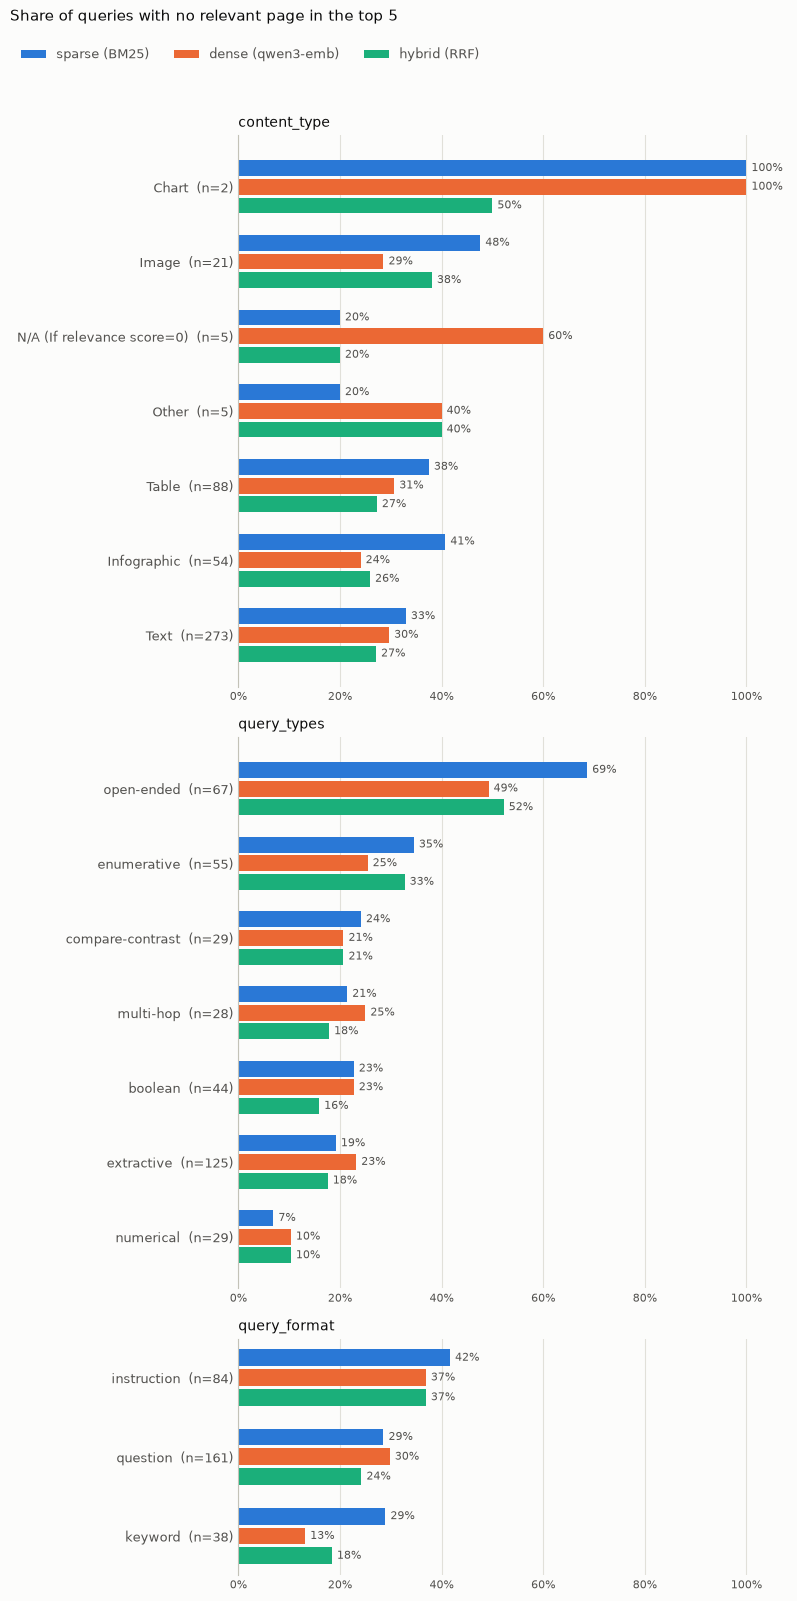

content_type


,sparse (BM25),dense (qwen3-emb),hybrid (RRF)
Chart (n=2),1.000,1.000,0.500
Image (n=21),0.476,0.286,0.381
N/A (If relevance score=0) (n=5),0.200,0.600,0.200
Other (n=5),0.200,0.400,0.400
Table (n=88),0.375,0.307,0.273
Infographic (n=54),0.407,0.241,0.259
Text (n=273),0.330,0.297,0.271


query_types


,sparse (BM25),dense (qwen3-emb),hybrid (RRF)
open-ended (n=67),0.687,0.493,0.522
enumerative (n=55),0.345,0.255,0.327
compare-contrast (n=29),0.241,0.207,0.207
multi-hop (n=28),0.214,0.250,0.179
boolean (n=44),0.227,0.227,0.159
extractive (n=125),0.192,0.232,0.176
numerical (n=29),0.069,0.103,0.103


query_format


,sparse (BM25),dense (qwen3-emb),hybrid (RRF)
instruction (n=84),0.417,0.369,0.369
question (n=161),0.286,0.298,0.242
keyword (n=38),0.289,0.132,0.184


In [12]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

DIMENSIONS = ["content_type", "query_types", "query_format"]
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua: one per retriever

queries_meta = ds_queries["test"].select_columns(["query_id", *DIMENSIONS]).to_pandas().set_index("query_id")

# A query is an error when none of its relevant pages is in the top K.
miss = pd.DataFrame({name: df[f"recall@{K}"] == 0 for name, df in per_query.items()}).astype(float)


def as_labels(value) -> list[str]:
    """Metadata can be a single label or a list of labels (a query can have several types)."""
    if value is None:
        return ["unknown"]
    if isinstance(value, (list, tuple, np.ndarray)):
        return [str(v) for v in value] or ["unknown"]
    return [str(value)]


def miss_rate_by(column: str) -> pd.DataFrame:
    """Miss rate per category (rows) and retriever (columns), worst category first."""
    labels = queries_meta.loc[miss.index, column].map(as_labels).explode().rename("category")
    rates = miss.join(labels).groupby("category").mean()
    counts = labels.value_counts()
    rates.index = [f"{c}  (n={counts[c]})" for c in rates.index]
    return rates.loc[rates.mean(axis=1).sort_values(ascending=False).index]


tables = {col: miss_rate_by(col) for col in DIMENSIONS}

BAR_H = 0.25  # one bar; three bars (one per retriever) make a category group
total_rows = sum(len(t) for t in tables.values())
fig_h = 1.6 + 0.85 * total_rows
fig, axes = plt.subplots(
    len(DIMENSIONS), 1,
    figsize=(8, fig_h),
    gridspec_kw={"height_ratios": [len(t) for t in tables.values()]},
    facecolor=SURFACE,
)
for ax, (col, rates) in zip(axes, tables.items()):
    ax.set_facecolor(SURFACE)
    y = np.arange(len(rates))
    for j, name in enumerate(rates.columns):
        offset = (j - (len(rates.columns) - 1) / 2) * BAR_H
        ax.barh(y + offset, rates[name], height=BAR_H * 0.85, color=SERIES_COLORS[j], label=name)
        for yy, v in zip(y + offset, rates[name]):
            ax.text(v + 0.01, yy, f"{v:.0%}", va="center", fontsize=8, color=INK_2)
    ax.set_yticks(y, rates.index, color=INK_2, fontsize=9)
    ax.invert_yaxis()  # worst category on top
    ax.set_xlim(0, 1.08)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis="x", colors=INK_2, labelsize=8, length=0)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("#c3c2b7")
    ax.set_title(col, loc="left", color=INK, fontsize=10)

handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(f"Share of queries with no relevant page in the top {K}", color=INK, fontsize=11,
             x=0.01, y=0.995, ha="left")
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 1 - 0.35 / fig_h), ncol=len(labels),
           frameon=False, labelcolor=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.7 / fig_h))
plt.show()

# Table view of the same numbers
for col, rates in tables.items():
    print(col)
    display(rates.round(3))

## Inspect BM25 misses on keyword queries

BM25 misses most keyword queries even though those should favour exact-term matching. This cell first counts how often BM25 and dense disagree across all queries. It then prints a random sample of keyword queries BM25 got wrong: the stemmed query terms, which of them appear in the best relevant page, and the text of that page next to BM25's top result. If the relevant page contains few of the query terms, the cause is a vocabulary mismatch. If it contains most of them, the BM25 setup is the thing to check.

In [13]:
import random

N_EXAMPLES = 5
SNIPPET_CHARS = 250

query_text = dict(zip(ds_queries["test"]["query_id"], ds_queries["test"]["query"]))
page_index = {pid: i for i, pid in enumerate(page_ids)}  # corpus_id -> position in page_texts

bm25_hit = per_query["sparse (BM25)"][f"recall@{K}"] > 0
dense_hit = per_query["dense (qwen3-emb)"][f"recall@{K}"] > 0

# Does BM25 find anything dense misses? If this is small, no fusion can gain much from BM25.
print(f"all queries: BM25 hit & dense miss = {(bm25_hit & ~dense_hit).sum()}, "
      f"dense hit & BM25 miss = {(~bm25_hit & dense_hit).sum()}, both hit = {(bm25_hit & dense_hit).sum()}")


def tokens(text: str) -> list[str]:
    """Same preprocessing BM25 applies: lowercase, drop English stopwords, stem."""
    return bm25s.tokenize(text, stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)[0]


def snippet(page_id: int) -> str:
    return " ".join(page_texts[page_index[page_id]].split())[:SNIPPET_CHARS]


keyword_misses = [
    qid for qid in bm25_hit.index
    if not bm25_hit[qid] and "keyword" in as_labels(queries_meta.at[qid, "query_format"])
]
print(f"keyword queries BM25 missed: {len(keyword_misses)}, of which dense found: {int(dense_hit[keyword_misses].sum())}\n")

for qid in random.Random(0).sample(keyword_misses, N_EXAMPLES):
    q_tokens = tokens(query_text[qid])
    relevant = sorted(qrels_by_query[qid])
    # The relevant page that shares the most query terms shows the best case for BM25.
    overlap = {pid: set(q_tokens) & set(tokens(page_texts[page_index[pid]])) for pid in relevant}
    best = max(relevant, key=lambda pid: len(overlap[pid]))
    top = sparse_pages(query_text[qid], K)

    print(f"query {qid}: {query_text[qid]!r}")
    print(f"  stemmed query terms: {q_tokens}")
    print(f"  relevant pages ({len(relevant)}): {relevant[:8]}   BM25 top {K}: {top}   dense found one: {bool(dense_hit[qid])}")
    print(f"  best relevant page {best} contains {sorted(overlap[best])}, missing {sorted(set(q_tokens) - overlap[best])}")
    print(f"  relevant page text: {snippet(best)}")
    print(f"  BM25 top-1 page text: {snippet(top[0])}\n")

all queries: BM25 hit & dense miss = 27, dense hit & BM25 miss = 35, both hit = 164
keyword queries BM25 missed: 11, of which dense found: 7

query 71: 'factors affecting aircraft servicing safety zones'
  stemmed query terms: ['factor', 'affect', 'aircraft', 'servic', 'safeti', 'zone']
  relevant pages (2): [2, 14]   BM25 top 5: [590, 2289, 638, 650, 593]   dense found one: False
  best relevant page 2 contains ['aircraft', 'safeti', 'servic'], missing ['affect', 'factor', 'zone']
  relevant page text: TO 00-25-172CL-2 ERATORS, AND REFUELING PERSONNEL (REO AND LVM) AT THE AIRCRAFT. The CSS will: a. Meet with aircraft loading supervisor to determine, define, or ensure air freight personnel and MHE operators are aware of the total requirements of con
  BM25 top-1 page text: TO 00-25-172 3.6 FUEL SERVICING SAFETY ZONE (FSSZ). This is the area within 50 feet of a pressurized fuel carrying servicing component; i.e., servicing hose, fuel nozzle, SPR, hy- drant hose cart, ramp hydrant connec